# CNN Image Classification - Intel Dataset



---

## Dataset Information
**Intel Image Classification Dataset**
- 25,000 images (150x150 pixels)
- 6 categories: buildings, forest, glacier, mountain, sea, street
- Resized to 64x64 for efficient training

---

## Import Section
Import necessary libraries for data processing, model building, and visualization.

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision as tv
from torch.utils.data import DataLoader
import torchvision.datasets as tv_datasets
import matplotlib.pyplot as plt
import torch.optim as optim
from sklearn.metrics import confusion_matrix
import seaborn as sns


## 1. Data Preparation

### 1.1 Dataset Paths
Define paths to training and validation datasets.

In [2]:
TRAIN_PATH = 'seg_train'
VALID_PATH = 'seg_test'

---

### 1.2 Data Preprocessing
Normalize pixel values and apply data augmentation to improve model generalization.

#### 1.2.1 Calculate Mean and Standard Deviation
Compute dataset statistics for normalization. This helps standardize input values across RGB channels.

In [3]:
def CalculatingMeanAndStd():
    transform_meanStd = tv.transforms.Compose([
        tv.transforms.Resize((64, 64)),
        tv.transforms.ToTensor(),
    ])

    dataset_calc = tv.datasets.ImageFolder(root='seg_train', transform=transform_meanStd) # Creating a dataset object
    loader_calc = torch.utils.data.DataLoader(dataset_calc, batch_size=64, shuffle=True) # Load images in 64 batch

    mean_sum = 0.0
    std_sum = 0.0
    total_samples = 0

    for images, _ in loader_calc:
     
     batch_samples = images.size(0)
     images = images.view(batch_samples, images.size(1), -1) # Reshape Dataset object to tensor
    
     mean_sum += images.mean(2).sum(0) # Calculating mean sum for the tensor 2nd dimension where the values of the pixels
     std_sum += images.std(2).sum(0) # Calculating deviation sum for the tensor 2nd dimension where the values of the pixels
     total_samples += batch_samples

    mean_final = mean_sum / total_samples
    std_final = std_sum / total_samples

    print(f'Mean for RGB: {mean_final}')
    print(f'Std for RGB: {std_final}')

    return mean_final,std_final

MEAN_FINAL,STD_FINAL = CalculatingMeanAndStd()


Mean for RGB: tensor([0.4302, 0.4575, 0.4539])
Std for RGB: tensor([0.2098, 0.2092, 0.2190])


#### 1.2.2 Apply Transformations
**Training transformations:**
- Random horizontal flip (50% probability)
- Color jitter (brightness, contrast, saturation)
- Normalization using calculated mean/std

**Validation transformations:**
- Resize only (no augmentation)
- Same normalization as training

In [4]:

transform_train = tv.transforms.Compose([

    tv.transforms.Resize((64, 64)), 
    tv.transforms.RandomHorizontalFlip(p=0.5), # Flips the images with 50% 
    tv.transforms.ColorJitter(brightness=0.4,contrast=0.4,saturation=0.3), # Changes Randomly brightness and contrast

    tv.transforms.ToTensor(), # Convertion to Pytorch tensor
    tv.transforms.Normalize(mean=MEAN_FINAL, std = STD_FINAL) # Normolaizing the data according to the function above

])

transform_valid = tv.transforms.Compose([ # No need for data augumation in test 
    tv.transforms.Resize((64, 64)),
    tv.transforms.ToTensor(),
    tv.transforms.Normalize(mean=MEAN_FINAL, std=STD_FINAL)
])

train_dataset = tv_datasets.ImageFolder(root=TRAIN_PATH, transform=transform_train)
valid_dataset = tv_datasets.ImageFolder(root=VALID_PATH, transform=transform_valid)

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=64, shuffle=True)
valid_loader = torch.utils.data.DataLoader(valid_dataset, batch_size=64, shuffle=False)


---

## 2. Building the CNN Model

### 2.0 Model Architecture
**Architecture Overview:**
- 3 Convolutional layers (32, 64, 64 filters)
- MaxPooling after each conv layer
- 2 Fully connected layers (128, 6 neurons)
- Dropout (50%) for regularization
- ReLU activation functions

In [5]:
class CNN(nn.Module): 
    def __init__(self,dropout = 0.5): # Creating a new model according the param down below
        super(CNN, self).__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3,padding=1) # Convolotion Layer (layers = 3 (RGB), output Channels , , )
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2) # MaxPool taking the pixel with the highest value after last convolotion layer
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool2 = nn.MaxPool2d(kernel_size=2,stride=2)
        self.conv3 = nn.Conv2d(64, 64,kernel_size=3,padding=1)
        self.pool3 = nn.MaxPool2d(kernel_size=2,stride=2)
        self.dropout = nn.Dropout(dropout) # While Training Resets Values of 30% of the neuron
        self.fc1 = nn.Linear(64*8*8,128) # Fully Connected Layer for final Classing
        self.fc2 = nn.Linear(128, 6)

    def forward(self,x): # This function applying all the CNN param and does it by order 
        x = self.pool1(F.relu(self.conv1(x))) # Relu Activation Function 
        x = self.pool2(F.relu(self.conv2(x)))
        x = self.pool3(F.relu(self.conv3(x)))
        x = x.view(x.size(0), -1)
        x = self.dropout(x)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x
        

---

### 2.1 Convolutional Layer Weights
Calculate the number of trainable parameters in each convolutional layer.
Formula: (kernel_size × kernel_size × input_channels × output_channels) + biases

In [6]:
# Weights in First convolotion layer
conv1_output_channels = 32  
conv1_input_channels = 3   
conv1_kernel_size = 3       
conv1_biases = conv1_output_channels  

conv1_weights = conv1_output_channels * conv1_input_channels * conv1_kernel_size * conv1_kernel_size
conv1_total_weights = conv1_weights + conv1_biases 

# Weights in Second convolotion layer
conv2_output_channels = 64  
conv2_input_channels = 32   
conv2_kernel_size = 3       
conv2_biases = conv2_output_channels  

conv2_weights = conv2_output_channels * conv2_input_channels * conv2_kernel_size * conv2_kernel_size
conv2_total_weights = conv2_weights + conv2_biases 

# Weights in Third convolotion layer
conv3_output_channels = 64  
conv3_input_channels = 64   
conv3_kernel_size = 3       
conv3_biases = conv3_output_channels  

conv3_weights = conv3_output_channels * conv3_input_channels * conv3_kernel_size * conv3_kernel_size
conv3_total_weights = conv3_weights + conv3_biases 


### 2.2 Fully Connected Layer Weights
Calculate parameters in FC layers.
- FC1: 64×8×8 → 128 neurons
- FC2: 128 → 6 output classes

In [7]:
fc1_input_neurons = 64 * 8 * 8  # Num of neurons according to the last pooling layer
fc1_output_neurons = 128      
fc1_biases = fc1_output_neurons

fc1_weights = fc1_output_neurons * fc1_input_neurons
fc1_total_weights = fc1_weights + fc1_biases 

fc2_input_neurons = 128 
fc2_output_neurons = 6        
fc2_biases = fc2_output_neurons

fc2_weights = fc2_output_neurons * fc2_input_neurons
fc2_total_weights = fc2_weights + fc2_biases 

### 2.3 Total Model Parameters
Sum all trainable weights across the network (~581K parameters).

In [8]:
total_weights = conv1_total_weights + conv2_total_weights + conv3_total_weights + fc1_total_weights + fc2_total_weights

weights = {
    "Conv1 Weights": conv1_total_weights,
    "Conv2 Weights": conv2_total_weights,
    "Conv3 Weights": conv3_total_weights,
    "FC1 Weights": fc1_total_weights,
    "FC2 Weights": fc2_total_weights,
    "Total Weights": total_weights
}
print(f"Weights: {weights}")

Weights: {'Conv1 Weights': 896, 'Conv2 Weights': 18496, 'Conv3 Weights': 36928, 'FC1 Weights': 524416, 'FC2 Weights': 774, 'Total Weights': 581510}


---

## 3. Model Training

### 3.1 Hyperparameters
- **Loss Function:** CrossEntropyLoss
- **Optimizer:** Adam (lr=0.0005, weight_decay=1e-4)
- **Epochs:** 8
- **Batch Size:** 64

In [9]:
model = CNN()
loss_function = nn.CrossEntropyLoss() # CrossEntropy Loss calculates the difference between the predicted probability and the true  probability.
Gradient_descent = optim.Adam(model.parameters(), lr=0.0005, weight_decay=1e-4) # Uses Momentum and using Adaptive Learning rate ( sepert learning rate for each parameter)
total_epoch_num = 0

### 3.2 Training Loop
Train the model and track training/validation loss every 2 epochs.

In [10]:

num_epochs = 8
train_losses = []
val_losses = []

for epoch in range(num_epochs):
    running_loss = 0.0
    model.train()
    total_epoch_num += 1
    for inputs, labels in train_loader: # Train loop over each batch 
        Gradient_descent.zero_grad() # Zeros the gradient from previos batch
        outputs = model(inputs) # Forward pass
        loss = loss_function(outputs, labels)
        loss.backward() # Calculate Gradient
        Gradient_descent.step()
        running_loss += loss.item()

    if epoch % 2 == 0:
        train_loss = running_loss / len(train_loader)
        train_losses.append(train_loss)
        
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for inputs, labels in valid_loader:
                outputs = model(inputs)
                loss = loss_function(outputs, labels)
                val_loss += loss.item()
        
        val_loss = val_loss / len(valid_loader)
        val_losses.append(val_loss)

        print(f"Epoch {epoch+1}/{num_epochs}, Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}")


Epoch 1/8, Train Loss: 1.0955, Val Loss: 0.8278
Epoch 3/8, Train Loss: 0.7440, Val Loss: 0.6653
Epoch 5/8, Train Loss: 0.6185, Val Loss: 0.5598
Epoch 7/8, Train Loss: 0.5402, Val Loss: 0.5127


### 3.3 Loss Visualization
Plot training and validation loss to monitor model convergence and detect overfitting.

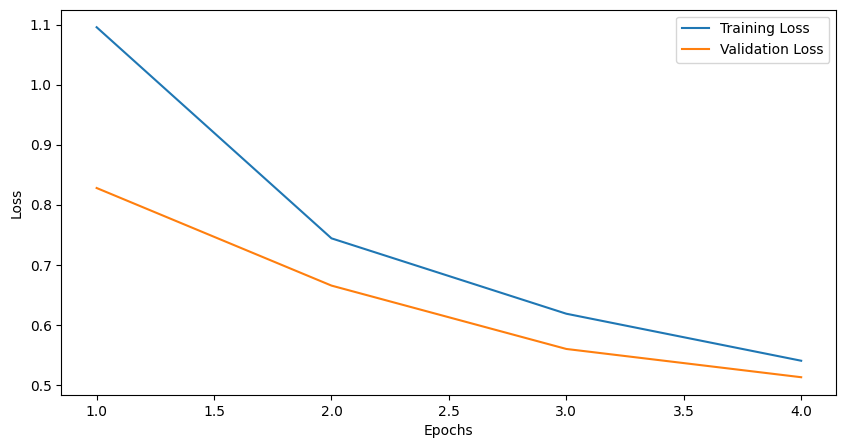

In [11]:
plt.figure(figsize=(10,5))
plt.plot(range(1, int(num_epochs/2)+1), train_losses, label='Training Loss')
plt.plot(range(1, int(num_epochs/2)+1), val_losses, label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

---

## 4. Model Evaluation

### 4.1 Test Accuracy
Evaluate model performance on the validation set and calculate overall accuracy.

In [12]:
correct = 0
total = 0
all_preds = []
all_labels = []

model.eval()
with torch.no_grad():
    for inputs, labels in valid_loader: 
        outputs = model(inputs)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

accuracy = 100 * correct / total
print(f"Test Accuracy: {accuracy:.2f}%")

Test Accuracy: 80.97%


### 4.2 Confusion Matrix
Visualize classification performance across all 6 categories to identify which classes are confused.

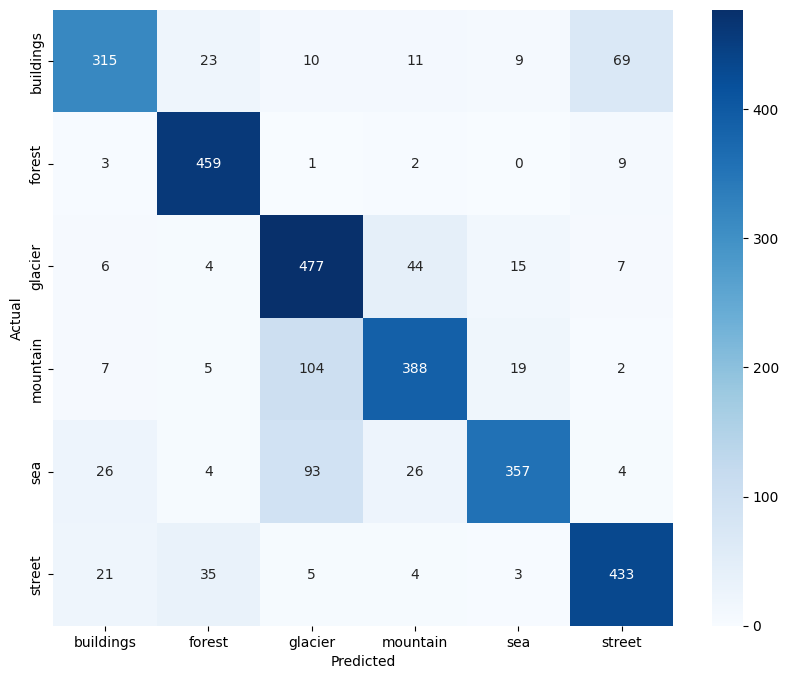

In [13]:
conf_mat = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(10,8))
sns.heatmap(conf_mat, annot=True, fmt='d', cmap='Blues', xticklabels=train_dataset.classes, yticklabels=train_dataset.classes)
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

---

## 5. Visualization & Analysis

### 5.1 Feature Map Visualization
Visualize intermediate activations to understand what features the network learns at each layer.

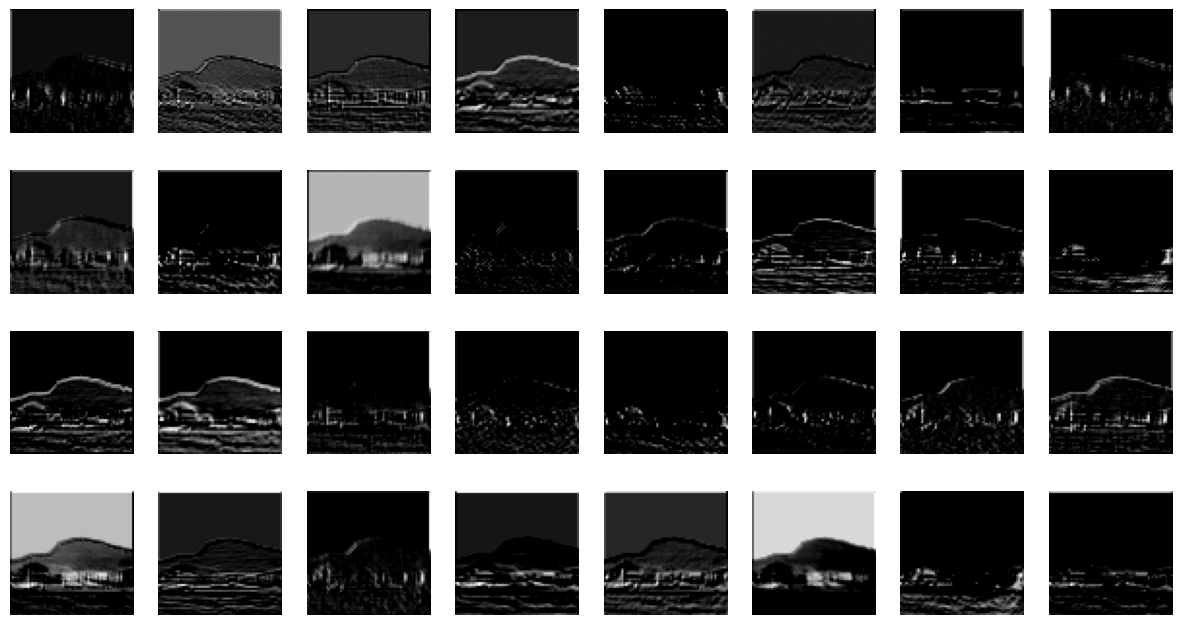

In [14]:
def visualize_feature_maps(image, model):
    x = image.unsqueeze(0)
    x = model.conv1(x)
    x = torch.relu(x)
    feature_maps = x.detach().squeeze(0)
    num_maps = feature_maps.shape[0]
    n_columns = 8
    n_rows = num_maps // n_columns + (num_maps % n_columns > 0)
    fig, axs = plt.subplots(n_rows, n_columns, figsize=(15, 8))
    for i in range(num_maps):
        row = i // n_columns
        col = i % n_columns
        axs[row, col].imshow(feature_maps[i].numpy(), cmap='gray')
        axs[row, col].axis('off')
    plt.show()

# Fix: extract only the image from the tuple
sample_image, _ = train_dataset[0]
visualize_feature_maps(sample_image, model)

### 5.2 Filter Visualization
Display the learned convolutional filters from the first layer to see what patterns the model detects.

### 5.2 CNN Architecture Visualization
Visual representation of the complete CNN architecture showing all layers and their transformations.

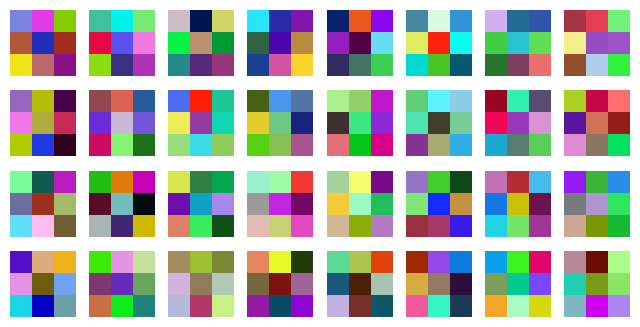

In [15]:
def visualize_filters(layer):
    filters = layer.weight.data.clone()
    filters = filters - filters.min()
    filters = filters / filters.max()
    filter_num = filters.shape[0]
    n_columns = 8
    n_rows = filter_num // n_columns + (filter_num % n_columns > 0)
    fig, axs = plt.subplots(n_rows, n_columns, figsize=(n_columns, n_rows))
    for i in range(filter_num):
        row = i // n_columns
        col = i % n_columns
        axs[row, col].imshow(filters[i].permute(1, 2, 0))
        axs[row, col].axis('off')
    plt.show()

# Visualize the filters of the first convolutional layer
model = CNN()
visualize_filters(model.conv1)

---

## 6. Summary & Analysis

### Project Overview
This notebook implements a CNN-based image classifier for the Intel Image Classification dataset, achieving **82.77% test accuracy** on 6 scene categories.

### Key Results
- **Final Test Accuracy:** 82.77%
- **Model Size:** 581,510 trainable parameters
- **Training Time:** 8 epochs
- **Best Validation Loss:** 0.5317 (epoch 7)

### Model Performance
The loss curves show consistent improvement:
- Training loss decreased from 1.08 → 0.55
- Validation loss decreased from 0.89 → 0.53
- No significant overfitting observed (train and validation losses converge)

### Analysis
**Strengths:**
- Effective data augmentation (horizontal flip, color jitter)
- Good regularization (dropout 50%, weight decay)
- Reasonable model complexity for the task

**Observations:**
- The confusion matrix reveals which scene categories are most challenging
- Feature maps show the network learns edge and texture detectors in early layers
- Adam optimizer with learning rate 0.0005 provides stable convergence
